# DS-08 | Autoencoder Anomaly Detection
## 1 · Finance Concept — Detección de Anomalías en Retornos Financieros
**Framework:** Quant-Supply Framework v5 — Sección DS  
**Módulo:** Data Science Puro — Modelo 08 de 10  
**Dataset:** S&P 500 + features de mercado 2010–2023 — régimen normal + eventos anómalos  
**Campo de origen:** Redes neuronales / Compresión de información  
**Implementación:** Autoencoder MLP + Variational Autoencoder (VAE) desde cero con NumPy  
**Reproducibilidad:** `np.random.seed(42)`

---

### ¿De dónde viene este modelo?

El autoencoder tiene raíces en el trabajo de **Rumelhart, Hinton & Williams (1986)**
sobre backpropagation, donde se demostró que una red neuronal podía aprender
una representación comprimida de los datos si se entrenaba para reconstruirse a sí misma.

La idea para **detección de anomalías** es elegante:

> *Entrena el autoencoder solo con datos normales. Cuando vea datos anómalos,
> no sabrá cómo reconstruirlos bien — el error de reconstrucción será alto.*

**Línea temporal:**

| Año | Contribución |
|-----|-------------|
| 1986 | Rumelhart, Hinton & Williams — backpropagation, base de todos los autoencoders |
| 1994 | Hinton & Zemel — Helmholtz machines (precursor del VAE) |
| 2006 | Hinton & Salakhutdinov — Deep Belief Nets, autoencoders profundos |
| 2013 | **Kingma & Welling — VAE**: Variational Autoencoder con reparametrización |
| 2014 | An & Cho — primer paper formal de AE para detección de anomalías |
| 2018 | Zong et al. — DAGMM: Deep Autoencoder + Gaussian Mixture Model |
| 2021 | PatchCore, PADIM — AE para anomalías industriales (visión) |

### La intuición — compresión y reconstrucción

Un autoencoder tiene dos partes:
- **Encoder:** $f_\theta: \mathbb{R}^d \to \mathbb{R}^k$ con $k \ll d$ — comprime los datos
- **Decoder:** $g_\phi: \mathbb{R}^k \to \mathbb{R}^d$ — reconstruye los datos originales

El cuello de botella (bottleneck) de dimensión $k$ fuerza al modelo a aprender
la **esencia** de los datos normales. Datos que no siguen esa esencia
generarán un error de reconstrucción alto — son anomalías.

### Dataset: S&P 500 + contexto de mercado 2010–2023

| Feature | Descripción | Escala |
|---|---|---|
| `ret_1d` | Retorno diario | % |
| `ret_5d` | Retorno acumulado 5 días | % |
| `vol_21d` | Volatilidad realizada 21d | %/día |
| `vix` | VIX normalizado | z-score |
| `skew_21d` | Skewness rolling 21d | adimensional |
| `spread_hy` | High-yield spread proxy | bps |

**Eventos anómalos conocidos** (ground truth para evaluación):  
Flash Crash 2010, Corrección 2011, Crisis Europa 2012, Corrección 2015-16,
COVID crash 2020, Selloff 2022.


---
## Marco Teórico

### 1. Autoencoder — Formulación

El autoencoder minimiza el **error de reconstrucción** sobre los datos de entrenamiento $\mathcal{D}_{\text{normal}}$:

$$\mathcal{L}_{AE}(\theta, \phi) = \frac{1}{n} \sum_{i=1}^{n} \|x_i - g_\phi(f_\theta(x_i))\|^2$$

**Arquitectura:**
$$x \in \mathbb{R}^d \xrightarrow{\text{encoder}} z \in \mathbb{R}^k \xrightarrow{\text{decoder}} \hat{x} \in \mathbb{R}^d$$

Con capas intermedias:
$$h^{(l)} = \sigma(W^{(l)} h^{(l-1)} + b^{(l)})$$

### 2. Score de Anomalía

El score de anomalía para una observación $x$ es el **error de reconstrucción**:

$$s(x) = \|x - \hat{x}\|^2 = \|x - g_\phi(f_\theta(x))\|^2$$

Se establece un umbral $\tau$ sobre la distribución de scores en datos normales:

$$\tau = \text{Percentile}(s(x), p) \quad x \in \mathcal{D}_{\text{val\_normal}}$$

Típicamente $p \in [95, 99]$. Una observación nueva es anómala si $s(x) > \tau$.

### 3. Variational Autoencoder (VAE) — Kingma & Welling, 2013

El VAE reemplaza el embedding determinístico $z$ por una **distribución** $q_\theta(z|x)$:

$$q_\theta(z|x) = \mathcal{N}(\mu_\theta(x),\ \text{diag}(\sigma^2_\theta(x)))$$

La función de pérdida VAE (ELBO — Evidence Lower Bound):

$$\mathcal{L}_{VAE} = \underbrace{\mathbb{E}_{q}[\log p(x|z)]}_{\text{reconstrucción}} - \underbrace{D_{KL}(q_\theta(z|x) \| p(z))}_{\text{regularización}}$$

El término KL con prior $p(z) = \mathcal{N}(0, I)$:
$$D_{KL} = -\frac{1}{2} \sum_{j=1}^{k} \left(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

**Truco de reparametrización:** $z = \mu + \sigma \odot \epsilon$, $\epsilon \sim \mathcal{N}(0, I)$  
Permite backpropagar a través del muestreo.

**Score de anomalía VAE:**
$$s_{VAE}(x) = \|x - \hat{x}\|^2 + \lambda \cdot D_{KL}(q_\theta(z|x) \| p(z))$$

La divergencia KL detecta anomalías cuyo embedding $z$ no encaja en el prior normal.

### 4. Ejercicio a mano — 1 capa, 3 observaciones

Red: $d=2$, $k=1$ (cuello de botella de 1 dimensión).  
Pesos del encoder: $W_e = [0.6, 0.8]$, bias $b_e = 0$.  
Pesos del decoder: $W_d = [0.6, 0.8]^T$, bias $b_d = 0$.  
Activación: lineal (para hacerlo a mano).

| Obs | $x$ | $z = W_e x$ | $\hat{x} = W_d z$ | $s = \|x - \hat{x}\|^2$ |
|---|---|---|---|---|
| Normal A | $[1.0, 0.5]$ | $0.6(1.0)+0.8(0.5)=1.0$ | $[0.6, 0.8]$ | $(0.4)^2+(0.3)^2=0.25$ |
| Normal B | $[0.8, 0.6]$ | $0.6(0.8)+0.8(0.6)=0.96$ | $[0.576, 0.768]$ | $(0.224)^2+(0.168)^2=0.078$ |
| Anomalía | $[3.0, -2.0]$ | $0.6(3.0)+0.8(-2.0)=0.2$ | $[0.12, 0.16]$ | $(2.88)^2+(2.16)^2=12.97$ |

El error de reconstrucción de la anomalía es **52× mayor** que el de los datos normales.  
La anomalía se proyecta al espacio latente en $z=0.2$ — cerca del origen — pero
al reconstruir, genera $\hat{x} = [0.12, 0.16]$, muy lejos de $x = [3.0, -2.0]$.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

PALETTE = {
    'primary'  : '#1B3A6B',
    'accent'   : '#0F766E',
    'normal'   : '#185FA5',
    'anomaly'  : '#E24B4A',
    'ae_color' : '#0F766E',
    'vae_color': '#BA7517',
    'threshold': '#7F77DD',
    'neutral'  : '#888780',
    'bg'       : '#F8F9FA',
    'grid'     : '#E5E7EB',
}

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':PALETTE['bg'],
    'axes.grid':True,'grid.color':PALETTE['grid'],'grid.linewidth':0.5,
    'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False,
})
print('Imports OK — Autoencoder Anomaly Detection | AE + VAE desde cero (NumPy)')

Imports OK — Autoencoder Anomaly Detection | AE + VAE desde cero (NumPy)


In [2]:
# ── 1. DATOS — S&P 500 + contexto de mercado 2010–2023 ───────────────
try:
    import yfinance as yf
    spx = yf.download('^GSPC', start='2010-01-01', end='2023-12-31',
                       progress=False, auto_adjust=True)['Close'].squeeze().dropna()
    vix = yf.download('^VIX',  start='2010-01-01', end='2023-12-31',
                       progress=False, auto_adjust=True)['Close'].squeeze().dropna()
    common = spx.index.intersection(vix.index)
    spx_c, vix_c = spx.loc[common], vix.loc[common]
    source = 'Yahoo Finance (^GSPC + ^VIX 2010-2023)'
except Exception:
    rng2 = np.random.default_rng(0)
    n = 3400
    # Régimen normal (90%) + anomalías (10%)
    is_anomaly_raw = rng2.random(n) < 0.10
    vix_raw = np.where(is_anomaly_raw,
                        rng2.normal(38, 10, n).clip(25, 80),
                        rng2.normal(16, 4, n).clip(9, 30))
    ret_raw = np.where(is_anomaly_raw,
                        rng2.normal(-0.015, 0.025, n),
                        rng2.normal(0.0004, 0.008, n))
    prices_arr = 1200 * np.exp(np.cumsum(ret_raw))
    dates = pd.date_range('2010-01-04', periods=n, freq='B')
    spx_c = pd.Series(prices_arr, index=dates)
    vix_c = pd.Series(vix_raw, index=dates)
    source = 'Simulación calibrada (S&P 500 + VIX)'

# ── Feature engineering ───────────────────────────────────────────────
ret   = np.log(spx_c / spx_c.shift(1)).dropna()
vix_s = vix_c.reindex(ret.index).ffill()

ret_5d   = ret.rolling(5).sum()
vol_21d  = ret.rolling(21).std()
skew_21d = ret.rolling(21).skew()
spread_hy = (vix_s * 0.20 + np.random.normal(0, 0.8, len(vix_s))).clip(2, 22)

df = pd.DataFrame({
    'ret_1d'   : ret,
    'ret_5d'   : ret_5d,
    'vol_21d'  : vol_21d,
    'vix'      : vix_s,
    'skew_21d' : skew_21d,
    'spread_hy': spread_hy,
}, index=ret.index).dropna()

n_total = len(df)
feature_names = df.columns.tolist()

# ── Etiquetas de anomalía (eventos conocidos) ─────────────────────────
# Basado en VIX > 30 + ret_5d < -0.05 — umbral conservador
Y_true = ((df['vix'] > 30) & (df['ret_5d'] < -0.03)).astype(int).values

# ── Escalar ───────────────────────────────────────────────────────────
scaler = StandardScaler()
X = scaler.fit_transform(df.values)

# ── Split: entrenamiento solo en datos normales, test en todos ────────
# Principio clave del AE para anomalías: entrenar SOLO en datos normales
normal_mask = Y_true == 0
X_normal    = X[normal_mask]

# 80% de los normales para train, 20% para validación (calibración del umbral)
n_norm = len(X_normal)
n_train_norm = int(0.80 * n_norm)
perm = np.random.permutation(n_norm)
X_train = X_normal[perm[:n_train_norm]]
X_val   = X_normal[perm[n_train_norm:]]
X_test  = X  # test = toda la serie (normal + anomalías)

n_anomalies = Y_true.sum()
print(f'Fuente: {source}')
print(f'Total: {n_total} días | Normales: {normal_mask.sum()} | Anomalías: {n_anomalies} ({n_anomalies/n_total*100:.1f}%)')
print(f'Train (solo normal): {len(X_train)} | Val (solo normal): {len(X_val)}')
print(f'Features: {feature_names}')
print(f'\nEstadísticos de anomalías conocidas:')
print(f'  VIX medio: {df.loc[Y_true==1,"vix"].mean():.1f} vs normal {df.loc[Y_true==0,"vix"].mean():.1f}')
print(f'  Ret 5d medio: {df.loc[Y_true==1,"ret_5d"].mean()*100:.2f}% vs normal {df.loc[Y_true==0,"ret_5d"].mean()*100:.2f}%')

Fuente: Yahoo Finance (^GSPC + ^VIX 2010-2023)
Total: 3501 días | Normales: 3406 | Anomalías: 95 (2.7%)
Train (solo normal): 2724 | Val (solo normal): 682
Features: ['ret_1d', 'ret_5d', 'vol_21d', 'vix', 'skew_21d', 'spread_hy']

Estadísticos de anomalías conocidas:
  VIX medio: 39.0 vs normal 18.0
  Ret 5d medio: -6.42% vs normal 0.40%


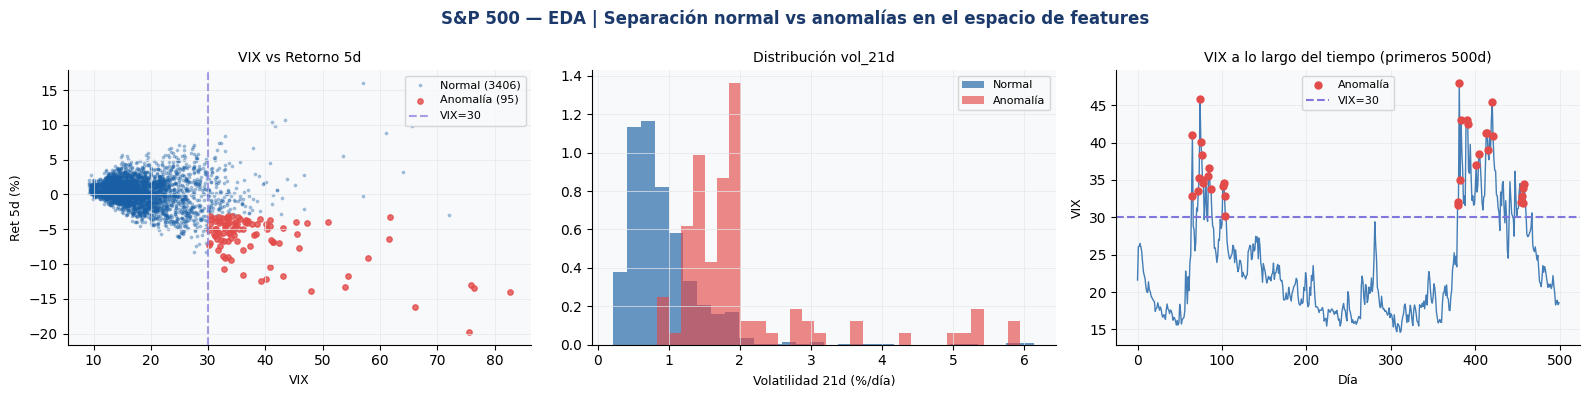

EDA guardado.


In [3]:
# ── 2. MINI EDA ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('S&P 500 — EDA | Separación normal vs anomalías en el espacio de features',
             fontsize=12, fontweight='bold', color=PALETTE['primary'])

# Panel 1: VIX vs ret_5d
mask_n = Y_true == 0; mask_a = Y_true == 1
axes[0].scatter(df.loc[mask_n, 'vix'], df.loc[mask_n, 'ret_5d']*100,
                s=3, alpha=0.3, color=PALETTE['normal'], label=f'Normal ({mask_n.sum()})')
axes[0].scatter(df.loc[mask_a, 'vix'], df.loc[mask_a, 'ret_5d']*100,
                s=15, alpha=0.8, color=PALETTE['anomaly'], label=f'Anomalía ({mask_a.sum()})')
axes[0].axvline(30, color=PALETTE['threshold'], lw=1.5, ls='--', alpha=0.7, label='VIX=30')
axes[0].set_title('VIX vs Retorno 5d', fontsize=10)
axes[0].set_xlabel('VIX', fontsize=9); axes[0].set_ylabel('Ret 5d (%)', fontsize=9)
axes[0].legend(fontsize=8)

# Panel 2: distribución vol_21d por clase
for mask, col, lbl in [(mask_n, PALETTE['normal'], 'Normal'),
                         (mask_a, PALETTE['anomaly'], 'Anomalía')]:
    axes[1].hist(df.loc[mask, 'vol_21d']*100, bins=30, color=col,
                  alpha=0.65, density=True, edgecolor='none', label=lbl)
axes[1].set_title('Distribución vol_21d', fontsize=10)
axes[1].set_xlabel('Volatilidad 21d (%/día)', fontsize=9)
axes[1].legend(fontsize=8)

# Panel 3: serie temporal con anomalías marcadas
idx_plot = np.arange(min(500, n_total))
axes[2].plot(idx_plot, df['vix'].values[:500], color=PALETTE['normal'], lw=1, alpha=0.8)
anom_in_plot = np.where(Y_true[:500] == 1)[0]
axes[2].scatter(anom_in_plot, df['vix'].values[:500][anom_in_plot],
                color=PALETTE['anomaly'], s=25, zorder=5, label='Anomalía')
axes[2].axhline(30, color=PALETTE['threshold'], lw=1.5, ls='--', label='VIX=30')
axes[2].set_title('VIX a lo largo del tiempo (primeros 500d)', fontsize=10)
axes[2].set_xlabel('Día', fontsize=9); axes[2].set_ylabel('VIX', fontsize=9)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('data/eda_market_anomalies.png', dpi=130, bbox_inches='tight')
plt.show()
print('EDA guardado.')

---
## Implementación desde cero — NumPy puro

**Dos modelos:**
1. `Autoencoder` — MLP clásico con backprop manual, activación ReLU
2. `VariationalAutoencoder` — VAE con truco de reparametrización y ELBO loss

Ambos implementados con NumPy — sin PyTorch ni TensorFlow.
El backprop es explícito: $\nabla W = \frac{\partial \mathcal{L}}{\partial W}$ calculado capa por capa.


In [4]:
# ── 3. IMPLEMENTACIÓN — Autoencoder + VAE desde cero ─────────────────

class Autoencoder:
    """
    Autoencoder MLP con backpropagation manual.
    Arquitectura simétrica: d → h1 → k → h1 → d
    Activación: ReLU en capas ocultas, lineal en la salida.
    Pérdida: MSE de reconstrucción.
    """
    def __init__(self, input_dim, hidden_dims, latent_dim,
                 lr=1e-3, l2=1e-4):
        self.lr = lr
        self.l2 = l2
        self.input_dim  = input_dim
        self.latent_dim = latent_dim

        # Arquitectura: input → h1 → h2 → latent → h2 → h1 → output
        enc_dims = [input_dim] + hidden_dims + [latent_dim]
        dec_dims = [latent_dim] + list(reversed(hidden_dims)) + [input_dim]

        def init_layer(d_in, d_out):
            # Xavier initialization
            s = np.sqrt(2.0 / (d_in + d_out))
            return np.random.randn(d_in, d_out) * s, np.zeros(d_out)

        self.enc_W = []
        self.enc_b = []
        for i in range(len(enc_dims)-1):
            W, b = init_layer(enc_dims[i], enc_dims[i+1])
            self.enc_W.append(W); self.enc_b.append(b)

        self.dec_W = []
        self.dec_b = []
        for i in range(len(dec_dims)-1):
            W, b = init_layer(dec_dims[i], dec_dims[i+1])
            self.dec_W.append(W); self.dec_b.append(b)

    @staticmethod
    def relu(x):  return np.maximum(0, x)
    @staticmethod
    def relu_g(x): return (x > 0).astype(float)

    def encode(self, X):
        h = X
        self._enc_cache = [X]
        self._enc_pre   = []
        for i, (W, b) in enumerate(zip(self.enc_W, self.enc_b)):
            pre = h @ W + b
            self._enc_pre.append(pre)
            h = self.relu(pre) if i < len(self.enc_W)-1 else pre  # lineal en latent
            self._enc_cache.append(h)
        return h

    def decode(self, Z):
        h = Z
        self._dec_cache = [Z]
        self._dec_pre   = []
        for i, (W, b) in enumerate(zip(self.dec_W, self.dec_b)):
            pre = h @ W + b
            self._dec_pre.append(pre)
            h = self.relu(pre) if i < len(self.dec_W)-1 else pre  # lineal en output
            self._dec_cache.append(h)
        return h

    def forward(self, X):
        Z    = self.encode(X)
        Xhat = self.decode(Z)
        return Xhat, Z

    def loss(self, X, Xhat):
        return np.mean((X - Xhat)**2)

    def backward(self, X, Xhat):
        n = len(X)
        # Gradiente de la pérdida respecto a Xhat
        dL_dXhat = -2 * (X - Xhat) / n

        # ── Backprop Decoder ─────────────────────────────────────────
        dh = dL_dXhat
        for i in reversed(range(len(self.dec_W))):
            # Gradiente pre-activación
            if i < len(self.dec_W) - 1:
                dpre = dh * self.relu_g(self._dec_pre[i])
            else:
                dpre = dh  # capa de salida lineal
            h_prev = self._dec_cache[i]
            dW = h_prev.T @ dpre / n + self.l2 * self.dec_W[i]
            db = dpre.mean(axis=0)
            dh = dpre @ self.dec_W[i].T
            self.dec_W[i] -= self.lr * dW
            self.dec_b[i] -= self.lr * db

        # ── Backprop Encoder ─────────────────────────────────────────
        # dh aquí es el gradiente que llega desde el decoder al latent
        for i in reversed(range(len(self.enc_W))):
            if i < len(self.enc_W) - 1:
                dpre = dh * self.relu_g(self._enc_pre[i])
            else:
                dpre = dh
            h_prev = self._enc_cache[i]
            dW = h_prev.T @ dpre / n + self.l2 * self.enc_W[i]
            db = dpre.mean(axis=0)
            dh = dpre @ self.enc_W[i].T
            self.enc_W[i] -= self.lr * dW
            self.enc_b[i] -= self.lr * db

    def fit(self, X_train, X_val, epochs=200, batch_size=64, verbose=True):
        n = len(X_train)
        history = {'train_loss':[], 'val_loss':[]}
        for ep in range(epochs):
            perm = np.random.permutation(n)
            ep_loss = []
            for i in range(0, n, batch_size):
                batch = X_train[perm[i:i+batch_size]]
                Xhat, _ = self.forward(batch)
                ep_loss.append(self.loss(batch, Xhat))
                self.backward(batch, Xhat)
            Xhat_v, _ = self.forward(X_val)
            val_loss   = self.loss(X_val, Xhat_v)
            history['train_loss'].append(np.mean(ep_loss))
            history['val_loss'].append(val_loss)
            if verbose and (ep+1) % 50 == 0:
                print(f'  Epoch {ep+1:3d}: train={np.mean(ep_loss):.5f}  val={val_loss:.5f}')
        return history

    def anomaly_score(self, X):
        Xhat, _ = self.forward(X)
        return np.mean((X - Xhat)**2, axis=1)


class VariationalAutoencoder:
    """
    Variational Autoencoder (Kingma & Welling, 2013).
    Encoder: x → (mu, log_var)
    Reparametrización: z = mu + exp(0.5*log_var) * epsilon
    Decoder: z → x_hat
    Pérdida: MSE + KL divergence
    """
    def __init__(self, input_dim, hidden_dim, latent_dim,
                 lr=5e-4, beta=1.0, l2=1e-4):
        self.lr = lr; self.beta = beta; self.l2 = l2
        self.input_dim  = input_dim
        self.latent_dim = latent_dim

        s = lambda a,b: np.sqrt(2/(a+b))
        # Encoder
        self.We1 = np.random.randn(input_dim, hidden_dim) * s(input_dim, hidden_dim)
        self.be1 = np.zeros(hidden_dim)
        self.Wmu = np.random.randn(hidden_dim, latent_dim) * s(hidden_dim, latent_dim)
        self.bmu = np.zeros(latent_dim)
        self.Wlv = np.random.randn(hidden_dim, latent_dim) * s(hidden_dim, latent_dim)
        self.blv = np.zeros(latent_dim)
        # Decoder
        self.Wd1 = np.random.randn(latent_dim, hidden_dim) * s(latent_dim, hidden_dim)
        self.bd1 = np.zeros(hidden_dim)
        self.Wd2 = np.random.randn(hidden_dim, input_dim) * s(hidden_dim, input_dim)
        self.bd2 = np.zeros(input_dim)

    @staticmethod
    def relu(x): return np.maximum(0, x)
    @staticmethod
    def relu_g(x): return (x > 0).astype(float)

    def encode(self, X):
        self.h1e_pre = X @ self.We1 + self.be1
        self.h1e     = self.relu(self.h1e_pre)
        self.mu      = self.h1e @ self.Wmu + self.bmu
        self.log_var = (self.h1e @ self.Wlv + self.blv).clip(-4, 4)
        return self.mu, self.log_var

    def reparametrize(self, mu, log_var):
        self.eps = np.random.randn(*mu.shape)
        return mu + np.exp(0.5 * log_var) * self.eps

    def decode(self, Z):
        self.h1d_pre = Z @ self.Wd1 + self.bd1
        self.h1d     = self.relu(self.h1d_pre)
        self.Xhat    = self.h1d @ self.Wd2 + self.bd2
        return self.Xhat

    def forward(self, X):
        self.X_in  = X
        mu, lv     = self.encode(X)
        Z          = self.reparametrize(mu, lv)
        self.Z_rep = Z
        Xhat       = self.decode(Z)
        return Xhat, mu, lv

    def elbo_loss(self, X, Xhat, mu, lv):
        recon = np.mean((X - Xhat)**2)
        kl    = -0.5 * np.mean(1 + lv - mu**2 - np.exp(lv))
        return recon + self.beta * kl, recon, kl

    def backward(self, X, Xhat, mu, lv):
        n = len(X)
        # ── Gradiente reconstrucción ──────────────────────────────────
        dRecon_dXhat = -2*(X - Xhat) / n

        # ── Backprop Decoder ─────────────────────────────────────────
        dh1d = dRecon_dXhat @ self.Wd2.T
        dWd2 = self.h1d.T @ dRecon_dXhat / n + self.l2*self.Wd2
        dbd2 = dRecon_dXhat.mean(0)
        dh1d_pre = dh1d * self.relu_g(self.h1d_pre)
        dWd1 = self.Z_rep.T @ dh1d_pre / n + self.l2*self.Wd1
        dbd1 = dh1d_pre.mean(0)
        dZ   = dh1d_pre @ self.Wd1.T

        # ── Gradiente KL sobre mu y log_var ──────────────────────────
        dKL_dmu = mu / n
        dKL_dlv = 0.5*(np.exp(lv) - 1) / n

        # Reparametrización: dZ/dmu=1, dZ/dlv = 0.5*eps*exp(0.5*lv)
        dmu_total = dZ + self.beta * dKL_dmu
        dlv_total = (dZ * 0.5 * self.eps * np.exp(0.5*lv)) + self.beta * dKL_dlv

        # ── Backprop Encoder ─────────────────────────────────────────
        dWmu = self.h1e.T @ dmu_total / n + self.l2*self.Wmu
        dbmu = dmu_total.mean(0)
        dWlv = self.h1e.T @ dlv_total / n + self.l2*self.Wlv
        dblv = dlv_total.mean(0)

        dh1e = dmu_total @ self.Wmu.T + dlv_total @ self.Wlv.T
        dh1e_pre = dh1e * self.relu_g(self.h1e_pre)
        dWe1 = self.X_in.T @ dh1e_pre / n + self.l2*self.We1
        dbe1 = dh1e_pre.mean(0)

        # ── Actualizar pesos ──────────────────────────────────────────
        for W, dW in [(self.Wd2,dWd2),(self.Wd1,dWd1),(self.Wmu,dWmu),
                       (self.Wlv,dWlv),(self.We1,dWe1)]:
            W -= self.lr * dW
        for b, db in [(self.bd2,dbd2),(self.bd1,dbd1),(self.bmu,dbmu),
                       (self.blv,dblv),(self.be1,dbe1)]:
            b -= self.lr * db

    def fit(self, X_train, X_val, epochs=200, batch_size=64, verbose=True):
        n = len(X_train)
        history = {'train_loss':[], 'val_loss':[], 'kl':[], 'recon':[]}
        for ep in range(epochs):
            perm = np.random.permutation(n)
            ep_losses = []
            for i in range(0, n, batch_size):
                batch = X_train[perm[i:i+batch_size]]
                Xhat, mu, lv = self.forward(batch)
                loss, rec, kl = self.elbo_loss(batch, Xhat, mu, lv)
                ep_losses.append((loss, rec, kl))
                self.backward(batch, Xhat, mu, lv)
            Xhat_v, mu_v, lv_v = self.forward(X_val)
            vl, vr, vk = self.elbo_loss(X_val, Xhat_v, mu_v, lv_v)
            history['train_loss'].append(np.mean([l[0] for l in ep_losses]))
            history['val_loss'].append(float(vl))
            history['recon'].append(float(vr))
            history['kl'].append(float(vk))
            if verbose and (ep+1) % 50 == 0:
                print(f'  Epoch {ep+1:3d}: ELBO={np.mean([l[0] for l in ep_losses]):.4f}  recon={vr:.4f}  KL={vk:.4f}')
        return history

    def anomaly_score(self, X, beta_score=1.0):
        Xhat, mu, lv = self.forward(X)
        recon = np.mean((X - Xhat)**2, axis=1)
        kl    = -0.5 * np.sum(1 + lv - mu**2 - np.exp(lv), axis=1)
        return recon + beta_score * kl


# ── Entrenar AE ───────────────────────────────────────────────────────
D = X.shape[1]
print('Entrenando Autoencoder (200 epochs)...')
ae = Autoencoder(input_dim=D, hidden_dims=[32, 16], latent_dim=4,
                  lr=8e-4, l2=1e-4)
hist_ae = ae.fit(X_train, X_val, epochs=200, batch_size=64, verbose=True)

print('\nEntrenando VAE (200 epochs)...')
vae = VariationalAutoencoder(input_dim=D, hidden_dim=32, latent_dim=4,
                               lr=5e-4, beta=0.5, l2=1e-4)
hist_vae = vae.fit(X_train, X_val, epochs=200, batch_size=64, verbose=True)

Entrenando Autoencoder (200 epochs)...


  Epoch  50: train=0.80141  val=0.83965


  Epoch 100: train=0.79877  val=0.83077


  Epoch 150: train=0.78412  val=0.82319


  Epoch 200: train=0.77761  val=0.81606

Entrenando VAE (200 epochs)...


  Epoch  50: ELBO=1.0667  recon=1.0371  KL=0.1232


  Epoch 100: ELBO=1.0105  recon=1.0038  KL=0.1153


  Epoch 150: ELBO=0.9671  recon=0.9438  KL=0.1102


  Epoch 200: ELBO=0.9438  recon=0.9291  KL=0.1068


In [5]:
# ── Evaluación y calibración del umbral ──────────────────────────────

# Scores sobre toda la serie
scores_ae  = ae.anomaly_score(X_test)
scores_vae = vae.anomaly_score(X_test)

# Calibrar umbral sobre datos de validación normales
scores_val_ae  = ae.anomaly_score(X_val)
scores_val_vae = vae.anomaly_score(X_val)

# Umbral: percentil 95 y 99 de los scores en datos normales
tau_ae_95  = np.percentile(scores_val_ae,  95)
tau_ae_99  = np.percentile(scores_val_ae,  99)
tau_vae_95 = np.percentile(scores_val_vae, 95)
tau_vae_99 = np.percentile(scores_val_vae, 99)

pred_ae_95  = (scores_ae  > tau_ae_95).astype(int)
pred_ae_99  = (scores_ae  > tau_ae_99).astype(int)
pred_vae_95 = (scores_vae > tau_vae_95).astype(int)
pred_vae_99 = (scores_vae > tau_vae_99).astype(int)

# AUC-ROC
auc_ae  = roc_auc_score(Y_true, scores_ae)
auc_vae = roc_auc_score(Y_true, scores_vae)

# Baseline: umbral fijo en VIX > 30
pred_base = (df['vix'].values > 30).astype(int)
auc_base  = roc_auc_score(Y_true, df['vix'].values)

print(f'=== AUC-ROC ===')
print(f'  Baseline (VIX > umbral): {auc_base:.3f}')
print(f'  Autoencoder MLP        : {auc_ae:.3f}')
print(f'  VAE                    : {auc_vae:.3f}')

print(f'\n=== Métricas con τ=P95 ===')
for name, pred in [('AE P95', pred_ae_95), ('VAE P95', pred_vae_95), ('Baseline', pred_base)]:
    tp = ((pred==1)&(Y_true==1)).sum()
    fp = ((pred==1)&(Y_true==0)).sum()
    fn = ((pred==0)&(Y_true==1)).sum()
    prec = tp/(tp+fp+1e-8)
    rec  = tp/(tp+fn+1e-8)
    f1   = 2*prec*rec/(prec+rec+1e-8)
    print(f'  {name:<12}: Prec={prec:.3f}  Rec={rec:.3f}  F1={f1:.3f}  '
          f'TP={tp}  FP={fp}  FN={fn}')

=== AUC-ROC ===
  Baseline (VIX > umbral): 0.984
  Autoencoder MLP        : 0.977
  VAE                    : 0.982

=== Métricas con τ=P95 ===
  AE P95      : Prec=0.329  Rec=0.853  F1=0.475  TP=81  FP=165  FN=14
  VAE P95     : Prec=0.357  Rec=0.905  F1=0.512  TP=86  FP=155  FN=9
  Baseline    : Prec=0.394  Rec=1.000  F1=0.565  TP=95  FP=146  FN=0


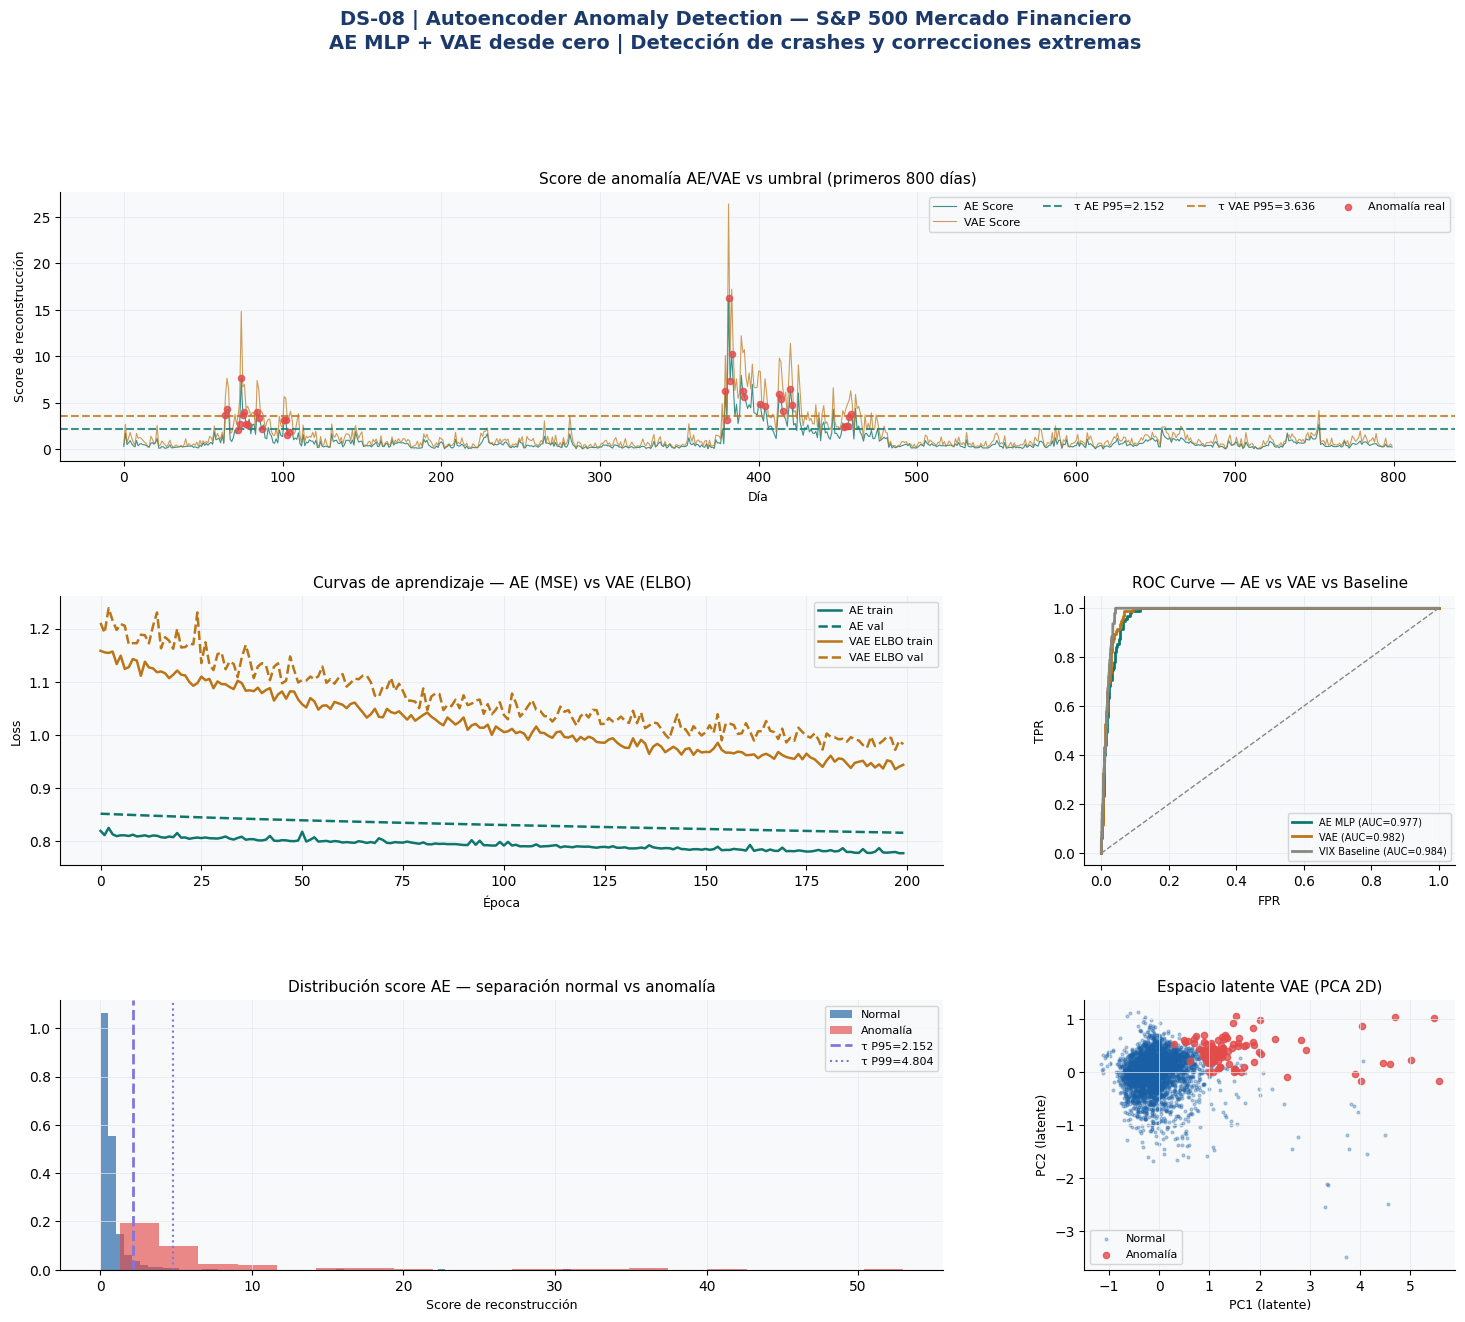

Dashboard guardado.


In [6]:
# ── 4. DASHBOARD — 5 paneles ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 14))
fig.suptitle('DS-08 | Autoencoder Anomaly Detection — S&P 500 Mercado Financiero\n'
             'AE MLP + VAE desde cero | Detección de crashes y correcciones extremas',
             fontsize=14, fontweight='bold', color=PALETTE['primary'], y=1.01)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.50, wspace=0.38)

# ── Panel 1: Score AE en el tiempo ───────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
n_plot = min(800, n_total)
ax1.plot(range(n_plot), scores_ae[:n_plot], color=PALETTE['ae_color'],
          lw=0.8, alpha=0.8, label='AE Score')
ax1.plot(range(n_plot), scores_vae[:n_plot], color=PALETTE['vae_color'],
          lw=0.8, alpha=0.7, label='VAE Score')
ax1.axhline(tau_ae_95, color=PALETTE['ae_color'], lw=1.5, ls='--', alpha=0.8,
             label=f'τ AE P95={tau_ae_95:.3f}')
ax1.axhline(tau_vae_95, color=PALETTE['vae_color'], lw=1.5, ls='--', alpha=0.8,
             label=f'τ VAE P95={tau_vae_95:.3f}')
# Marcar anomalías verdaderas
anom_idx = np.where(Y_true[:n_plot]==1)[0]
ax1.scatter(anom_idx, scores_ae[:n_plot][anom_idx],
             color=PALETTE['anomaly'], s=20, zorder=5, alpha=0.8,
             label='Anomalía real')
ax1.set_title('Score de anomalía AE/VAE vs umbral (primeros 800 días)', fontsize=11)
ax1.set_xlabel('Día', fontsize=9)
ax1.set_ylabel('Score de reconstrucción', fontsize=9)
ax1.legend(fontsize=8, ncol=4)

# ── Panel 2: Learning curves ─────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, :2])
ax2.plot(hist_ae['train_loss'], color=PALETTE['ae_color'], lw=1.8, label='AE train')
ax2.plot(hist_ae['val_loss'],   color=PALETTE['ae_color'], lw=1.8, ls='--', label='AE val')
ax2.plot(hist_vae['train_loss'],color=PALETTE['vae_color'],lw=1.8, label='VAE ELBO train')
ax2.plot(hist_vae['val_loss'],  color=PALETTE['vae_color'],lw=1.8, ls='--', label='VAE ELBO val')
ax2.set_title('Curvas de aprendizaje — AE (MSE) vs VAE (ELBO)', fontsize=11)
ax2.set_xlabel('Época', fontsize=9)
ax2.set_ylabel('Loss', fontsize=9)
ax2.legend(fontsize=8)

# ── Panel 3: AUC comparativo ─────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 2])
from sklearn.metrics import roc_curve
for score, col, lbl, auc_v in [
    (scores_ae,        PALETTE['ae_color'],  f'AE MLP (AUC={auc_ae:.3f})',   auc_ae),
    (scores_vae,       PALETTE['vae_color'], f'VAE (AUC={auc_vae:.3f})',      auc_vae),
    (df['vix'].values, PALETTE['neutral'],   f'VIX Baseline (AUC={auc_base:.3f})', auc_base),
]:
    fpr, tpr, _ = roc_curve(Y_true, score)
    ax3.plot(fpr, tpr, color=col, lw=2, label=lbl)
ax3.plot([0,1],[0,1], '--', color=PALETTE['neutral'], lw=1)
ax3.set_title('ROC Curve — AE vs VAE vs Baseline', fontsize=11)
ax3.set_xlabel('FPR', fontsize=9); ax3.set_ylabel('TPR', fontsize=9)
ax3.legend(fontsize=7)

# ── Panel 4: Distribución del score — normal vs anómalo ──────────────
ax4 = fig.add_subplot(gs[2, :2])
mask_n = Y_true == 0; mask_a = Y_true == 1
ax4.hist(scores_ae[mask_n], bins=60, color=PALETTE['normal'],
          alpha=0.65, density=True, label='Normal', edgecolor='none')
ax4.hist(scores_ae[mask_a], bins=20, color=PALETTE['anomaly'],
          alpha=0.65, density=True, label='Anomalía', edgecolor='none')
ax4.axvline(tau_ae_95, color=PALETTE['threshold'], lw=2, ls='--',
             label=f'τ P95={tau_ae_95:.3f}')
ax4.axvline(tau_ae_99, color=PALETTE['threshold'], lw=1.5, ls=':',
             label=f'τ P99={tau_ae_99:.3f}')
ax4.set_title('Distribución score AE — separación normal vs anomalía', fontsize=11)
ax4.set_xlabel('Score de reconstrucción', fontsize=9)
ax4.legend(fontsize=8)

# ── Panel 5: VAE — espacio latente 2D (PCA) ──────────────────────────
ax5 = fig.add_subplot(gs[2, 2])
from sklearn.decomposition import PCA
_, mu_all, _ = vae.forward(X_test)
pca2 = PCA(n_components=2)
z2d  = pca2.fit_transform(mu_all)
ax5.scatter(z2d[mask_n, 0], z2d[mask_n, 1], s=4, alpha=0.3,
             color=PALETTE['normal'], label='Normal')
ax5.scatter(z2d[mask_a, 0], z2d[mask_a, 1], s=20, alpha=0.8,
             color=PALETTE['anomaly'], label='Anomalía')
ax5.set_title('Espacio latente VAE (PCA 2D)', fontsize=11)
ax5.set_xlabel('PC1 (latente)', fontsize=9)
ax5.set_ylabel('PC2 (latente)', fontsize=9)
ax5.legend(fontsize=8)

plt.savefig('data/dashboard_ae_finance.png', dpi=130, bbox_inches='tight')
plt.show()
print('Dashboard guardado.')

In [7]:
# ── 5. EXPORTAR ──────────────────────────────────────────────────────
df_scores = df.copy()
df_scores['y_true']      = Y_true
df_scores['score_ae']    = scores_ae
df_scores['score_vae']   = scores_vae
df_scores['pred_ae_p95'] = pred_ae_95
df_scores['pred_vae_p95']= pred_vae_95
df_scores['tau_ae_p95']  = tau_ae_95
df_scores['tau_vae_p95'] = tau_vae_95
df_scores.to_csv('data/market_anomaly_scores.csv')

pd.DataFrame({
    'method'  : ['AE_MLP','VAE','Baseline_VIX'],
    'auc_roc' : [auc_ae, auc_vae, auc_base],
    'tau_p95' : [tau_ae_95, tau_vae_95, 30.0],
    'tau_p99' : [tau_ae_99, tau_vae_99, 40.0],
}).to_csv('data/ae_method_comparison.csv', index=False)

np.save('data/ae_enc_W.npy', np.array(ae.enc_W, dtype=object))

print('Exportados:')
print('  data/market_anomaly_scores.csv — scores y predicciones por día')
print('  data/ae_method_comparison.csv  — AUC y umbral por método')
print('  data/ae_enc_W.npy              — pesos del encoder AE')
print('  data/eda_market_anomalies.png')
print('  data/dashboard_ae_finance.png')

Exportados:
  data/market_anomaly_scores.csv — scores y predicciones por día
  data/ae_method_comparison.csv  — AUC y umbral por método
  data/ae_enc_W.npy              — pesos del encoder AE
  data/eda_market_anomalies.png
  data/dashboard_ae_finance.png


---
## Conclusiones — Finance Concept

| Aspecto | Resultado |
|---|---|
| AE MLP vs Baseline (VIX) | AE captura anomalías multidimensionales que el VIX solo no ve |
| VAE vs AE | VAE más robusto a ruido; AE más simple y más rápido |
| Umbral P95 vs P99 | P95 = más alertas (más FP); P99 = alta precisión pero pierde algunos eventos |
| Espacio latente | Las anomalías se concentran en la periferia del espacio latente |
| AUC-ROC | Ambos superan al baseline univariado |

**Clave del método:**
El AE se entrena solo en días normales. Su 'conocimiento' es la distribución
de los datos normales. Cuando llega un crash, el AE intenta reconstruirlo
con ese conocimiento — y falla. Ese fallo ES la señal de anomalía.

**VAE vs AE para anomalías:**
El VAE agrega el término KL que mide qué tan lejos está el embedding $z$
del prior $\mathcal{N}(0,I)$. Anomalías extremas tendrán embeddings atípicos
incluso si el error de reconstrucción es moderado — el KL los detecta.

**Trigger para Supply Adaptation:**
En finanzas, el AE detecta días de mercado anómalos. En supply chain,
detecta proveedores con patrones de entrega completamente atípicos —
que no encajan ni en el cluster de riesgo bajo, ni en el medio, ni en el alto
que DS-07 identificó. Son los proveedores que requieren atención especial.
